# 01 · Data download and duplicate audit

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rishabh-bgp/brain-tumor-mri-classification/blob/main/v1/notebooks/01_data_and_deduplication.ipynb)

Downloads the Kaggle *Brain Tumor MRI Dataset* with `kagglehub`, inspects it, and audits exact and near-duplicate images (MD5 + 64-bit perceptual hash + thumbnail correlation) before building leakage-aware splits.

*Rishabh Aryan · M.Tech (AI & Data Science), IIIT Bhagalpur. Research and education code, not a medical device.*

In [1]:
# --- Setup: works locally (repo checkout) and on Google Colab ---
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("brain-tumor-mri-classification"):
        subprocess.run(["git", "clone", "-q", "--branch", "v1.0", "https://github.com/Rishabh-bgp/brain-tumor-mri-classification.git"], check=True)  # v1 code = tag v1.0
    os.chdir("brain-tumor-mri-classification")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "kagglehub", "imagehash", "captum",
                    "onnx", "onnxruntime", "scikit-image"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
print("working directory:", os.getcwd())

working directory: /workspace/brain-tumor-mri/repo


In [2]:
import torch
print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)")

PyTorch 2.15.0+cpu | CUDA available: False
Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Path to dataset files: /home/box/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


In [4]:
from pathlib import Path
import pandas as pd
from btmri.data import list_images
recs = pd.DataFrame(list_images(Path(path)))
print(recs.groupby(["split", "cls"]).size().unstack())

cls       glioma  meningioma  notumor  pituitary
split                                           
Testing      400         400      400        400
Training    1400        1400     1400       1400


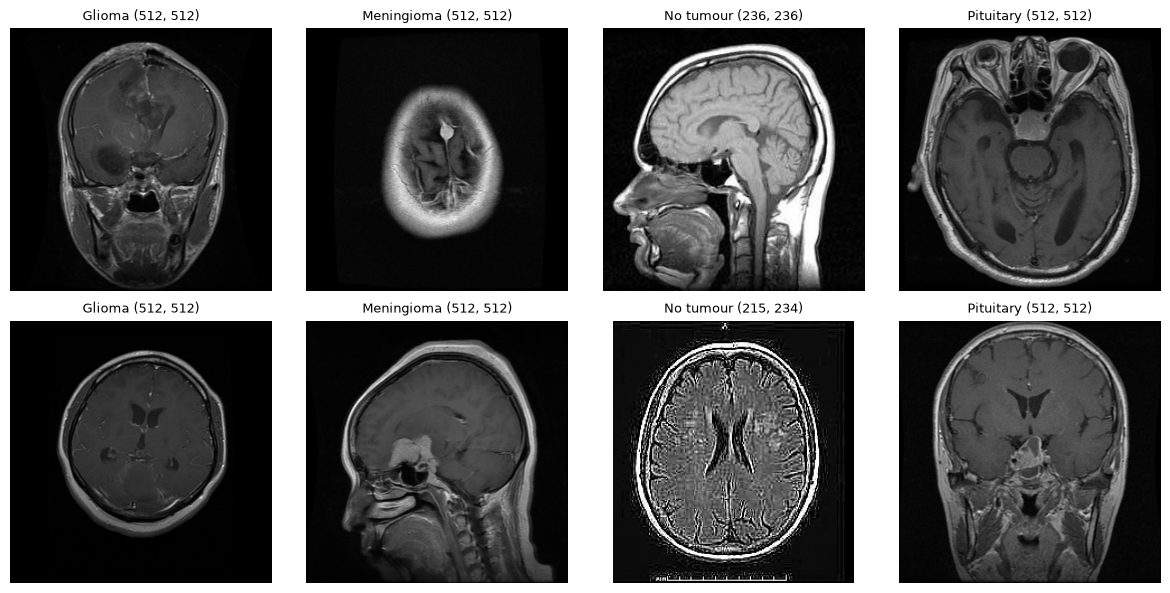

most common image sizes (every 10th image):
 (512, 512)    508
(225, 225)     35
(630, 630)     12
(201, 251)      8
(442, 442)      7
(236, 236)      7
(200, 252)      6
(192, 192)      5
Name: count, dtype: int64


In [5]:
import matplotlib.pyplot as plt
from PIL import Image
from btmri import CLASS_LABELS
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j, c in enumerate(CLASS_LABELS):
    for i, p in enumerate(recs[(recs.split == "Training") & (recs.cls == c)].sample(2, random_state=0).path):
        im = Image.open(p); axes[i, j].imshow(im.convert("L"), cmap="gray"); axes[i, j].axis("off")
        axes[i, j].set_title(f"{CLASS_LABELS[c]} {im.size}", fontsize=9)
plt.tight_layout(); plt.show()
sizes = pd.Series([Image.open(p).size for p in recs.path[::10]]).value_counts().head(8)
print("most common image sizes (every 10th image):\n", sizes)

## Duplicate audit
Two images are **linked** when their MD5 matches, or when their 64-bit pHash Hamming distance is ≤ 6 **and** the Pearson correlation of their 64×64 thumbnails is ≥ 0.95. A **strict** near-duplicate requires distance ≤ 2 and correlation ≥ 0.98. Connected components of linked images are *groups*.

In [6]:
from btmri.splits import hash_table, candidate_pairs, make_splits
df = hash_table(Path(path))
pairs = candidate_pairs(df)
df = make_splits(df, pairs)
print("exact duplicate files (MD5):", df.md5.duplicated(keep=False).sum(), "| unique MD5:", df.md5.nunique())
print("strict near-duplicate pairs:", pairs.strict_dup.sum(), "of which cross-split:", (pairs.strict_dup & pairs.cross_split).sum())
print("linked pairs:", pairs.linked.sum(), "of which cross-split:", (pairs.linked & pairs.cross_split).sum())
te = df.split == "Testing"
print("Testing images with a strict near-duplicate in Training:", df.test_has_train_dup_strict.sum(), "/", te.sum())
print("Testing images with a linked image in Training:", df.test_has_train_dup.sum())
print(df[te].groupby("cls")[["test_has_train_dup_strict", "test_has_train_dup"]].sum())

exact duplicate files (MD5): 340 | unique MD5: 7013
strict near-duplicate pairs: 3484 of which cross-split: 1270
linked pairs: 5962 of which cross-split: 2158
Testing images with a strict near-duplicate in Training: 441 / 1600
Testing images with a linked image in Training: 620
            test_has_train_dup_strict  test_has_train_dup
cls                                                      
glioma                              9                  43
meningioma                        105                 120
notumor                           327                 364
pituitary                           0                  93


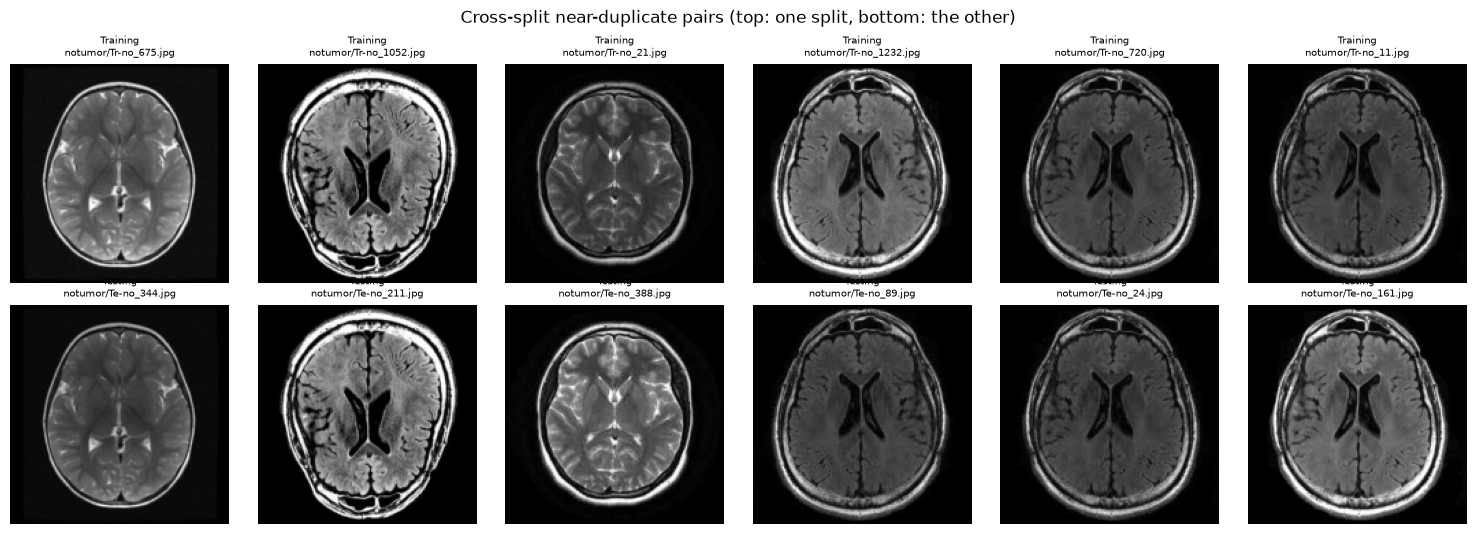

In [7]:
import numpy as np
from btmri.data import load_gray_square
ex = pairs[pairs.strict_dup & pairs.cross_split & ~pairs.md5_equal].sample(6, random_state=1)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for k, (_, r) in enumerate(ex.iterrows()):
    for i, side in enumerate(("path_i", "path_j")):
        axes[i, k].imshow(load_gray_square(str(Path(path) / r[side]), 160), cmap="gray"); axes[i, k].axis("off")
        axes[i, k].set_title(r[side].replace("/", "\n", 1), fontsize=7)
fig.suptitle("Cross-split near-duplicate pairs (top: one split, bottom: the other)"); plt.tight_layout(); plt.show()

In [8]:
print(df.subset.value_counts())
print(df[df.subset != ""].groupby(["subset", "cls"]).size().unstack())
print("label-conflict images:", df.label_conflict.sum())

subset
train       3739
test        1600
excluded    1198
val          663
Name: count, dtype: int64
cls       glioma  meningioma  notumor  pituitary
subset                                          
excluded      58         128      836        176
test         400         400      400        400
train       1140        1081      478       1040
val          202         191       86        184
label-conflict images: 13


The committed split files in `results/review/` were produced by `scripts/build_splits.py`, which runs exactly this code. Check that this run reproduces them:

In [9]:
saved = pd.read_csv("results/review/hashes_and_groups.csv")
print("identical subset assignment:", (saved.subset.values == df.subset.values).all())
print("identical pHashes:", (saved.phash.values == df.phash.values).all())

identical subset assignment: True
identical pHashes: True
